# Rapport : moteur d'analyse de flux de logs

Projet Python ING3 ECE. Ce notebook illustre le fonctionnement du pipeline : il
l'exécute sur un petit échantillon (`demo_data/echantillon.log`), montre le résultat
de chaque module, puis trace deux graphiques à partir du jeu de démonstration complet.

**Chaîne de traitement :** lecture (`yield` / `yield from`) → parsing en dictionnaires
→ `filter` → `map` → moteur de règles → agrégation → rapports `globals()` / `locals()`.

Le code du projet reste dans les modules `.py` ; ce notebook ne sert qu'à la démonstration.

In [1]:
import contextlib
import io
import os
import tracemalloc
from collections import defaultdict
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt

# Les chemins du projet sont relatifs à la racine : on s'y place si besoin.
if Path.cwd().name == "report":
    os.chdir(Path.cwd().parent)

import main as pipeline
from src.agregation import brute_force_detector
from src.ingestion import extract_blacklist_ips, lire_all_logs, lire_logs, parse_logs
from src.rules_engine import apply_security_rules
from src.transfo import filtrage_logs, normalize_logs, router_log

ECHANTILLON = "demo_data/echantillon.log"
BLACKLIST = "demo_data/blacklist.txt"
DEMO = ["demo_data/auth.log", "demo_data/network.log", "demo_data/server.log"]


def lancer_sans_affichage(fichiers: list[str]) -> tuple[str, list[str]]:
    """Lance le pipeline en capturant son affichage (un print par log).

    Renvoie le dossier du rapport et les messages de lignes rejetées.
    """
    tampon = io.StringIO()
    with contextlib.redirect_stdout(tampon):
        dossier = pipeline.lancer_pipeline(fichiers, BLACKLIST)
    rejets = [ligne for ligne in tampon.getvalue().splitlines() if " Erreur: " in ligne]
    return dossier, rejets

## 1. Lancement du pipeline sur l'échantillon

L'échantillon contient 15 lignes bien formées ou presque, une ligne illisible et une
ligne vide. Il inclut volontairement un payload en texte brut, un payload JSON sans
`event`, et une série de 5 échecs de connexion depuis une IP blacklistée.

In [2]:
print(Path(ECHANTILLON).read_text(encoding="utf-8"))

2026-10-15T08:00:00 level=INFO ip=192.168.1.13 user=alice payload={"event":"login_success","success":true}
2026-10-15T08:00:05 level=ERROR ip=192.168.1.13 user=alice payload={"event":"login_failed","success":false}
2026-10-15T08:00:10 level=INFO ip=192.168.1.13 user=alice payload={"event":"login_success","success":true}
2026-10-15T08:01:00 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:02 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:04 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:06 level=ERROR ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:01:08 level=CRITICAL ip=10.0.0.99 user=admin payload={"event":"login_failed","success":false}
2026-10-15T08:02:00 level=ERROR ip=192.168.1.50 user=bob payload={"event":"login_failed","success":false}
2026-10-15T08:02:05 level=WARNING ip=192.168

In [3]:
dossier, rejets = lancer_sans_affichage([ECHANTILLON])
context = pipeline.context

print("Fichiers du rapport :", sorted(p.name for p in Path(dossier).iterdir()))
print(f"\nLignes rejetées sans plantage : {len(rejets)}")
for message in rejets:
    print(" -", message)

Fichiers du rapport : ['report_global.txt', 'report_local.txt']

Lignes rejetées sans plantage : 3
 - ligne 15 Erreur: le payload ne contient pas event fichier demo_data/echantillon.log
 - ligne 16 Erreur: list index out of range fichier demo_data/echantillon.log
 - ligne 17 Erreur: list index out of range fichier demo_data/echantillon.log


## 2. Module 1 : ingestion et générateurs

`lire_logs` est un générateur : rien n'est lu tant qu'on ne demande pas une ligne.
`lire_all_logs` enchaîne plusieurs fichiers avec `yield from`.

In [4]:
gen = lire_logs(ECHANTILLON)
print("Type :", type(gen).__name__)
print("Première ligne demandée :", next(gen))

enchaine = lire_all_logs([ECHANTILLON, BLACKLIST])
print("\nLignes lues sur 2 fichiers avec yield from :", sum(1 for _ in enchaine))

Type : generator
Première ligne demandée : ('2026-10-15T08:00:00 level=INFO ip=192.168.1.13 user=alice payload={"event":"login_success","success":true}', 1, 'demo_data/echantillon.log')

Lignes lues sur 2 fichiers avec yield from : 19


**Gain mémoire.** On compare le pic de mémoire entre un parcours paresseux de tout le
jeu de démonstration et le chargement de ces mêmes lignes dans une liste.

In [5]:
def pic_memoire(fonction) -> tuple[int, float]:
    tracemalloc.start()
    nombre = fonction()
    _, pic = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return nombre, pic / 1024 / 1024


lignes_gen, pic_gen = pic_memoire(lambda: sum(1 for _ in lire_all_logs(DEMO)))
lignes_liste, pic_liste = pic_memoire(lambda: len(list(lire_all_logs(DEMO))))

print(f"Générateur : {lignes_gen} lignes, pic de {pic_gen:.2f} Mo")
print(f"Liste      : {lignes_liste} lignes, pic de {pic_liste:.2f} Mo")

Générateur : 37018 lignes, pic de 0.03 Mo
Liste      : 37018 lignes, pic de 9.39 Mo


**Parsing.** Chaque ligne devient un dictionnaire. Les métadonnées fixes sont rangées
dans un tuple immuable `(IP, Port, Protocole)`. Une ligne invalide donne `None`.

In [6]:
lignes = list(islice(lire_logs(ECHANTILLON), 16))

connexion = parse_logs(lignes[12])
print("Dictionnaire :", connexion)
print("Tuple de métadonnées :", connexion["metadata"], type(connexion["metadata"]).__name__)
print("Payload brut conservé :", parse_logs(lignes[13])["payload"])
print("Ligne illisible :", parse_logs(lignes[15]))

Dictionnaire : {'time': '2026-10-15 08:04:00', 'level': 'INFO', 'ip': '192.168.1.22', 'user': 'service', 'payload': {'event': 'tcp_connection', 'port': 443, 'protocol': 'TCP'}, 'metadata': ('192.168.1.22', 443, 'TCP')}
Tuple de métadonnées : ('192.168.1.22', 443, 'TCP') tuple
Payload brut conservé : connexion refusee par le pare-feu
ligne 16 Erreur: list index out of range fichier demo_data/echantillon.log
Ligne illisible : None


## 3. Module 2 : transformations fonctionnelles

`filtrage_logs` combine `filter` et `lambda` pour retirer les lignes invalides ;
`map` applique ensuite `normalize_logs` à chaque enregistrement.

In [7]:
with contextlib.redirect_stdout(io.StringIO()):
    parses = list(map(parse_logs, lire_logs(ECHANTILLON)))
    valides = list(filtrage_logs(iter(parses)))
    normalises = list(map(normalize_logs, valides))

print(f"Avant filter : {len(parses)} | après filter : {len(valides)}")
print("\nAvant normalisation :", valides[12])
print("Après normalisation :", normalises[12])

Avant filter : 17 | après filter : 14

Avant normalisation : {'time': '2026-10-15 08:04:00', 'level': 'INFO', 'ip': '192.168.1.22', 'user': 'service', 'payload': {'event': 'tcp_connection', 'port': 443, 'protocol': 'TCP'}, 'metadata': ('192.168.1.22', 443, 'TCP')}
Après normalisation : {'TIME': '2026-10-15 08:04:00', 'LEVEL': 'INFO', 'IP': '192.168.1.22', 'USER': 'SERVICE', 'PAYLOAD': {'EVENT': 'TCP_CONNECTION', 'PORT': 443, 'PROTOCOL': 'TCP'}, 'METADATA': ('192.168.1.22', 443, 'TCP')}


**Routage `match-case`.** `router_log` choisit le format selon la structure de l'élément :
chaîne brute, dictionnaire ou tuple de connexion.

In [8]:
exemples = [
    "connexion refusee",
    {"LEVEL": "ERROR", "PAYLOAD": {"STATUS": 500}},
    {"LEVEL": "CRITICAL"},
    {"LEVEL": "INFO"},
    ("10.0.0.1", 443, "TCP"),
    ("10.0.0.1", None, None),
    42,
]
for element in exemples:
    print(f"{str(element):<50} -> {router_log(element)}")

print("\nFormats comptés par le pipeline sur l'échantillon :")
for nom, total in sorted(context["formats"].items()):
    print(f"  {nom:<28} {total}")

connexion refusee                                  -> CHAINE BRUTE
{'LEVEL': 'ERROR', 'PAYLOAD': {'STATUS': 500}}     -> DICT ERREUR (code 500)
{'LEVEL': 'CRITICAL'}                              -> DICT ERREUR
{'LEVEL': 'INFO'}                                  -> DICT
('10.0.0.1', 443, 'TCP')                           -> TUPLE CONNEXION
('10.0.0.1', None, None)                           -> TUPLE SANS CONNEXION
42                                                 -> FORMAT INCONNU

Formats comptés par le pipeline sur l'échantillon :
  DICT                         6
  DICT ERREUR                  7
  DICT ERREUR (code 500)       1
  PAYLOAD CHAINE BRUTE         1
  PAYLOAD DICT                 13
  TUPLE CONNEXION              1
  TUPLE SANS CONNEXION         13


## 4. Module 3 : agrégation

**Ensembles.** `unique_ips` est un `set` des IP ayant généré des erreurs ; la blacklist
est un `frozenset` immuable. Les quatre opérations mathématiques les comparent.

In [9]:
ips_erreurs = context["unique_ips"]
blacklist = extract_blacklist_ips(BLACKLIST)

print(f"IP ayant généré des erreurs ({type(ips_erreurs).__name__}) :", sorted(ips_erreurs))
print(f"Blacklist ({type(blacklist).__name__}) :", sorted(blacklist))
print("\nUnion (|)                 :", sorted(ips_erreurs | blacklist))
print("Intersection (&)          :", sorted(ips_erreurs & blacklist))
print("Différence (-)            :", sorted(ips_erreurs - blacklist))
print("Différence symétrique (^) :", sorted(ips_erreurs ^ blacklist))

IP ayant généré des erreurs (set) : ['10.0.0.99', '192.168.1.13', '192.168.1.21', '192.168.1.50']
Blacklist (frozenset) : ['10.0.0.99', '203.0.113.45']

Union (|)                 : ['10.0.0.99', '192.168.1.13', '192.168.1.21', '192.168.1.50', '203.0.113.45']
Intersection (&)          : ['10.0.0.99']
Différence (-)            : ['192.168.1.13', '192.168.1.21', '192.168.1.50']
Différence symétrique (^) : ['192.168.1.13', '192.168.1.21', '192.168.1.50', '203.0.113.45']


**`defaultdict`.** Une clé absente vaut 0 : on peut incrémenter sans `KeyError`.

In [10]:
compteur = defaultdict(int)
compteur["cle_jamais_vue"] += 1
print("Incrément d'une clé absente :", dict(compteur))

print("\nPar niveau :", dict(context["occurence_error"]))
print("Par utilisateur :", dict(context["occurence_user"]))

Incrément d'une clé absente : {'cle_jamais_vue': 1}

Par niveau : {'ERROR': 7, 'CRITICAL': 1, 'WARNING': 2}
Par utilisateur : {'ALICE': 1, 'ADMIN': 5, 'BOB': 2, 'GUEST': 1, 'SERVICE': 1}


**Détection de force brute.** Un compteur d'échecs consécutifs est tenu par IP et remis
à zéro après une connexion réussie. L'IP devient suspecte à partir du seuil, fixé à 5
dans `main.py`.

In [11]:
print("Échecs consécutifs par IP :", dict(context["occurence_brute_force"]))
print("IP suspectes :", sorted(context["ip_sus_brute_force"]))
print("Suspectes hors blacklist :", sorted(context["ip_sus_brute_force"] - blacklist))

Échecs consécutifs par IP : {'192.168.1.13': 0, '10.0.0.99': 5, '192.168.1.50': 2, '192.168.1.20': 0, '192.168.1.21': 0, '192.168.1.22': 0, '192.168.1.23': 0}
IP suspectes : ['10.0.0.99']
Suspectes hors blacklist : []


## 5. Module 4 : moteur de règles et introspection

`apply_security_rules(*args, **kwargs)` reçoit des fonctions en argument (`*args`) et des
paramètres de configuration (`**kwargs`). On lui ajoute ici une règle écrite sur place,
et on abaisse le seuil, sans modifier le moteur.

In [12]:
def regle_compter_admin(log: dict, context: dict, **kwargs) -> None:
    if log.get("USER") == "ADMIN":
        context["logs_admin"] += 1


contexte_test = {
    "occurence_brute_force": defaultdict(int),
    "ip_sus_brute_force": set(),
    "logs_admin": 0,
}
for log in normalises:
    variables_locales = apply_security_rules(
        brute_force_detector,
        regle_compter_admin,
        log=log,
        context=contexte_test,
        seuil_brute_force=2,
    )

print("Logs de l'utilisateur ADMIN :", contexte_test["logs_admin"])
print("Suspectes avec un seuil à 2 :", sorted(contexte_test["ip_sus_brute_force"]))
print("\nVariables renvoyées par locals() :", sorted(variables_locales))
print("Règles reçues dans *args :", [r.__name__ for r in variables_locales["args"]])
print("Paramètres reçus dans **kwargs :", sorted(variables_locales["kwargs"]))

Logs de l'utilisateur ADMIN : 5
Suspectes avec un seuil à 2 : ['10.0.0.99', '192.168.1.50']

Variables renvoyées par locals() : ['args', 'kwargs', 'rule']
Règles reçues dans *args : ['brute_force_detector', 'regle_compter_admin']
Paramètres reçus dans **kwargs : ['context', 'log', 'seuil_brute_force']


**Audit `globals()` / `locals()`.** Le pipeline exporte dans `report_global.txt` les
variables en mémoire, avec leur type et leur taille.

In [13]:
rapport = (Path(dossier) / "report_global.txt").read_text(encoding="utf-8")
print(rapport[rapport.index("[AUDIT VARIABLES LOCALES"):])

[AUDIT VARIABLES LOCALES (locals)]
- dossier_rapport : str, 67 octets 
- fichier_blacklist : str, 64 octets 
- fichiers_logs : list, 64 octets 
- filtered_logs : generator, 200 octets 
- horodatage : str, 60 octets 
- line_log : dict, 272 octets 
- normalized_logs : map, 48 octets 
- parsed_logs : map, 48 octets 
- raw_logs : generator, 208 octets 

[AUDIT VARIABLES GLOBALES (globals)]
- apply_security_rules : function, 160 octets 
- blacklist_ips : frozenset, 216 octets 
- brute_force_detector : function, 160 octets 
- compter_formats : function, 160 octets 
- context : dict, 464 octets 
- datetime : type, 416 octets 
- defaultdict : type, 944 octets 
- extract_blacklist_ips : function, 160 octets 
- extract_unique_error_ips : function, 160 octets 
- filtrage_logs : function, 160 octets 
- introspection_audit : function, 160 octets 
- introspection_global : function, 160 octets 
- introspection_local : function, 160 octets 
- lancer_pipeline : function, 160 octets 
- lire_all_logs : f

## 6. Graphiques sur le jeu de démonstration complet

Le pipeline traite ici les trois fichiers de démonstration, soit environ 37 000 lignes.

In [14]:
dossier_demo, rejets_demo = lancer_sans_affichage(DEMO)
contexte_demo = pipeline.context

print(f"Rapport : {dossier_demo}")
print(f"Lignes rejetées : {len(rejets_demo)}")

Rapport : report\2026-11-08_21-30-58
Lignes rejetées : 7


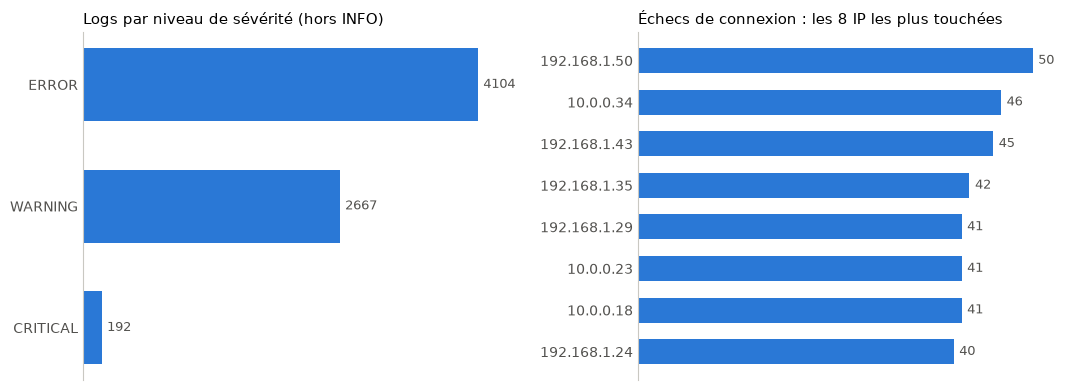

IP suspectes de force brute : ['10.0.0.14', '10.0.0.18', '10.0.0.99', '192.168.1.11', '192.168.1.22', '192.168.1.43', '192.168.1.50', '203.0.113.45']


In [15]:
BLEU = "#2a78d6"
ENCRE = "#52514e"


def barres(ax, donnees: dict, titre: str) -> None:
    """Trace des barres horizontales, de la plus grande à la plus petite."""
    tri = sorted(donnees.items(), key=lambda paire: paire[1])
    noms = [str(nom) for nom, _ in tri]
    valeurs = [valeur for _, valeur in tri]
    rects = ax.barh(noms, valeurs, color=BLEU, height=0.6)
    ax.bar_label(rects, padding=4, color=ENCRE, fontsize=9)
    ax.set_title(titre, loc="left", fontsize=11)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.spines["left"].set_color("#c9c8c2")
    ax.tick_params(axis="y", length=0, colors=ENCRE)
    ax.xaxis.set_visible(False)
    ax.margins(x=0.12)


echecs = contexte_demo["echecs_par_ip"]
top_echecs = dict(sorted(echecs.items(), key=lambda paire: paire[1], reverse=True)[:8])

fig, (gauche, droite) = plt.subplots(1, 2, figsize=(11, 4))
barres(gauche, dict(contexte_demo["occurence_error"]), "Logs par niveau de sévérité (hors INFO)")
barres(droite, top_echecs, "Échecs de connexion : les 8 IP les plus touchées")
fig.tight_layout()
plt.show()

print("IP suspectes de force brute :", sorted(contexte_demo["ip_sus_brute_force"]))

## 7. Bilan

Le pipeline traite les fichiers ligne par ligne, écarte les lignes invalides sans
s'interrompre, et produit à chaque exécution un rapport horodaté dans `report/`.

Pour relancer le projet : `python main.py` (fichiers de démonstration) ou
`python start.py` (menu de choix des fichiers).